## Step 0 – Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize as so
from scipy import stats

np.set_printoptions(precision=6, suppress=True)

## Step 1 – Load data

`pd.read_excel` reads a sheet into a DataFrame. The file needs the columns `Date`, `Market_Index` and `Stock_Price` on the sheet `Prices` (this needs the `openpyxl` package, which pandas uses to read `.xlsx`). The notebook and the Excel file must be in the same folder.

In [3]:
df = pd.read_excel("stock_market_prices.xlsx", sheet_name="Prices", parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True)
print(df.shape)
df.head()

(61, 3)


,Date,Market_Index,Stock_Price
0,2021-01-31,4000.00,150.00
1,2021-02-28,3914.68,149.95
2,2021-03-31,3915.22,153.25
3,2021-04-30,4239.66,174.94
4,2021-05-31,4399.33,184.76


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          61 non-null     datetime64[ns]
 1   Market_Index  61 non-null     float64       
 2   Stock_Price   61 non-null     float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 1.6 KB


## Step 2 – Compute returns from prices

Regression is done on **returns**, not prices (prices are not comparable across assets). The simple monthly return is

$$ r_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{P_t}{P_{t-1}} - 1 .$$

We define $x_t$ = market return (explanatory variable) and $y_t$ = stock return (response). The first row has no previous price, so it is dropped.

number of observations: 60
mean / std of market return: 0.0041 0.0445
mean / std of stock return : 0.008 0.0655


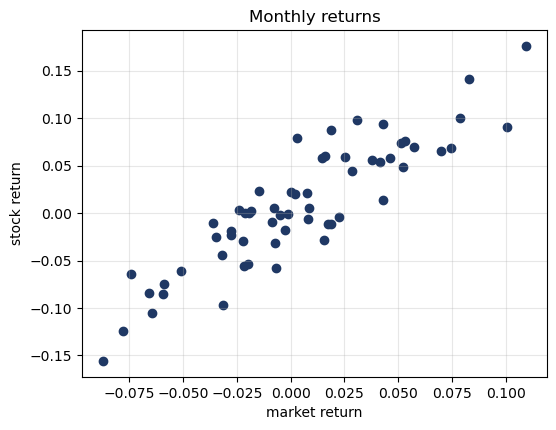

In [5]:
df["Market_Return"] = df["Market_Index"].pct_change()
df["Stock_Return"]  = df["Stock_Price"].pct_change()
df = df.dropna().reset_index(drop=True)

x = df["Market_Return"].to_numpy()   # explanatory variable
y = df["Stock_Return"].to_numpy()    # response
n = len(x)
print("number of observations:", n)
print("mean / std of market return:", x.mean().round(4), x.std(ddof=1).round(4))
print("mean / std of stock return :", y.mean().round(4), y.std(ddof=1).round(4))

plt.figure(figsize=(6, 4.5))
plt.scatter(x, y, color="#1F3864")
plt.xlabel("market return"); plt.ylabel("stock return")
plt.title("Monthly returns"); plt.grid(alpha=0.3); plt.show()

## Step 3 – The model

We assume each stock return is a straight line in the market return plus independent Gaussian noise:

$$ y_t = \alpha + \beta\, x_t + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal N(0,\sigma^2), \quad t=1,\dots,n .$$

Equivalently, each observation is normally distributed around the line:

$$ y_t \mid x_t \;\sim\; \mathcal N\!\left(\alpha+\beta x_t,\ \sigma^2\right). $$

The unknown parameter vector is $\theta = (\alpha,\beta,\sigma)$.

## Step 4 – The likelihood and the negative log-likelihood

The density of one observation is

$$ f(y_t \mid x_t;\theta) = \frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\left(-\frac{(y_t-\alpha-\beta x_t)^2}{2\sigma^2}\right). $$

Observations are independent, so the likelihood of the whole sample is the product

$$ L(\theta)=\prod_{t=1}^{n} f(y_t\mid x_t;\theta). $$

Taking logs turns the product into a sum (easier to differentiate, and numerically safe):

$$ \ell(\theta)=\ln L(\theta) = -\frac{n}{2}\ln(2\pi) - n\ln\sigma - \frac{1}{2\sigma^2}\sum_{t=1}^{n}(y_t-\alpha-\beta x_t)^2 . $$

The maximum likelihood estimate is $\hat\theta=\arg\max_\theta \ell(\theta)$. Optimizers in SciPy **minimize**, so we minimize

$$ \text{NLL}(\theta) = -\ell(\theta). $$

**Parametrization trick.** $\sigma$ must be positive, but we do not want to require this through a constraint to optimization method.. We optimize over $s=\ln\sigma$ and set $\sigma=e^{s}$, which is positive for every real $s$. The optimizer works with $(\alpha,\beta,s)$.

**Observation.** For fixed $\sigma$, only the last term depends on $(\alpha,\beta)$: maximizing $\ell$ over $(\alpha,\beta)$ is the same as minimizing the sum of squared errors – **MLE with Gaussian noise equals least squares.**

In [5]:
def nll(theta, x, y):
    """Negative log-likelihood of the Gaussian linear regression model.
    theta = (alpha, beta, log_sigma)."""
    alpha, beta, log_sigma = theta
    sigma = np.exp(log_sigma)
    resid = y - (alpha + beta * x)
    n = len(y)
    return 0.5 * n * np.log(2 * np.pi) + n * log_sigma + np.sum(resid**2) / (2 * sigma**2)

# quick check: the NLL is lower for parameters close to the truth than for poor ones
print(nll([0.002, 1.3, np.log(0.03)], x, y))   # near the data-generating values
print(nll([0.0,   0.0, np.log(0.03)], x, y))   # a flat line - much worse

-126.54919331598052
-12.546666390201352


## Step 5 – Solve the MLE problem with Nelder–Mead

**Nelder–Mead** (downhill simplex) is a derivative-free method: it keeps $n+1$ points in $n$ dimensions (a triangle for 2 parameters, a tetrahedron for 3), and repeatedly reflects, expands, contracts or shrinks the simplex using only comparisons of function values.

We need a **starting point** $\theta_0$. Reasonable choices: $\alpha_0=0$, $\beta_0=1$, and $\sigma_0$ = standard deviation of $y$. We also tighten the tolerances (`xatol`, `fatol`): returns are small numbers (about 0.01–0.05), and the default tolerances can stop too early.

In [6]:
theta0 = np.array([0.0, 1.0, np.log(y.std())])

res_nm = so.minimize(nll, theta0, args=(x, y), method="Nelder-Mead",
                     options={"xatol": 1e-10, "fatol": 1e-12, "maxiter": 10000, "maxfev": 10000})

alpha_mle, beta_mle, sigma_mle = res_nm.x[0], res_nm.x[1], np.exp(res_nm.x[2])
print(res_nm.message)
print("iterations:", res_nm.nit, "  function evaluations:", res_nm.nfev)
print(f"alpha_hat = {alpha_mle:.6f}")
print(f"beta_hat  = {beta_mle:.6f}")
print(f"sigma_hat = {sigma_mle:.6f}")
print(f"NLL at optimum = {res_nm.fun:.4f}")

Optimization terminated successfully.
iterations: 132   function evaluations: 260
alpha_hat = 0.002578
beta_hat  = 1.312291
sigma_hat = 0.029335
NLL at optimum = -126.6019


## Step 6 – Check against the closed-form solution

For this model the MLE can also be found by hand. Setting $\partial\ell/\partial\alpha=0$ and $\partial\ell/\partial\beta=0$ gives the **normal equations**, with solution

$$ \hat\beta=\frac{\sum_t (x_t-\bar x)(y_t-\bar y)}{\sum_t (x_t-\bar x)^2}=\frac{S_{xy}}{S_{xx}}, \qquad \hat\alpha=\bar y-\hat\beta\,\bar x, $$

and setting $\partial\ell/\partial\sigma=0$ gives

$$ \hat\sigma^2=\frac{1}{n}\sum_t (y_t-\hat\alpha-\hat\beta x_t)^2 = \frac{\text{SSE}}{n}. $$

(The MLE divides by $n$, not $n-2$, so it is slightly biased downward in small samples.) A numerical optimizer must reproduce these numbers – a very useful test of the code.

In [7]:
Sxy = np.sum((x - x.mean()) * (y - y.mean()))
Sxx = np.sum((x - x.mean())**2)
beta_cf  = Sxy / Sxx
alpha_cf = y.mean() - beta_cf * x.mean()
sse = np.sum((y - alpha_cf - beta_cf * x)**2)
sigma_cf = np.sqrt(sse / n)

cmp = pd.DataFrame({"closed form": [alpha_cf, beta_cf, sigma_cf],
                    "Nelder-Mead MLE": [alpha_mle, beta_mle, sigma_mle],
                    "true (simulation)": [0.002, 1.3, 0.03]},
                   index=["alpha", "beta", "sigma"])
cmp["abs. difference"] = (cmp["closed form"] - cmp["Nelder-Mead MLE"]).abs()
cmp

,closed form,Nelder-Mead MLE,true (simulation),abs. difference
alpha,0.002578,0.002578,0.002,1.561891e-10
beta,1.312291,1.312291,1.300,8.310127e-09
sigma,0.029335,0.029335,0.030,1.566090e-10


### Visualizing the likelihood surface

Fix $\alpha=\hat\alpha$ and $\sigma=\hat\sigma$ and look at the NLL as a function of $\beta$ only. The minimum of this curve is the MLE, and its width reflects the standard error found in Step 8.

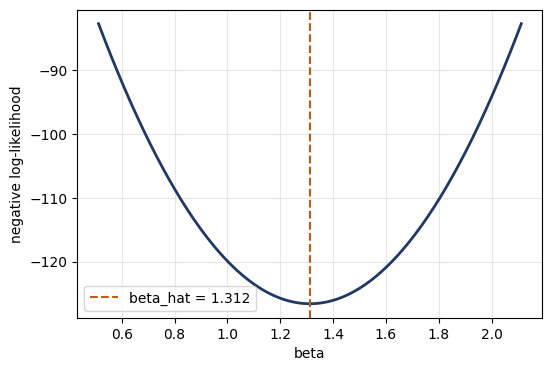

In [12]:
betas = np.linspace(beta_mle - 0.8, beta_mle + 0.8, 200)
curve = [nll([alpha_mle, b, np.log(sigma_mle)], x, y) for b in betas]
plt.figure(figsize=(6, 4))
plt.plot(betas, curve, color="#1F3864", lw=2)
plt.axvline(beta_mle, color="#C55A11", ls="--", label=f"beta_hat = {beta_mle:.3f}")
plt.xlabel("beta"); plt.ylabel("negative log-likelihood"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## Interpretation

* $\hat\beta$ is the estimated market sensitivity: when the market moves by 1 %, the stock moves by about $\hat\beta$ % on average.
* $\hat\alpha$ is the average monthly return unexplained by the market (with real data a *positive and significant* $\alpha$ would be unusual).
* $\hat\sigma$ is the monthly stock-specific risk that cannot be explained by the market.
* The numerical MLE (Nelder–Mead and other optimizers) agrees with the closed-form least-squares solution, which confirms that **maximum likelihood with Gaussian noise = least squares**. The optimization route matters because it keeps working for models with no closed form (logistic regression, heavy-tailed noise, neural networks).

**Try it yourself**
1. Replace the Gaussian noise by Student-$t$ noise (heavy tails, more realistic for returns): write the new NLL and re-run Step 5 – there is no closed form any more.
2. Use *excess* returns (subtract a risk-free rate) to get the proper CAPM regression.
3. Add a second explanatory variable (e.g. a sector index) and extend $\theta$.

## Optional – use real data

The cell below downloads real month-end prices with the `yfinance` package (`pip install yfinance`, internet connection required) and writes them in the same format, so the rest of the notebook runs unchanged. Change the tickers as you like (`^GSPC` = S&P 500). Set `USE_REAL_DATA = True` to run it, then re-run the notebook from Step 1.

In [13]:
USE_REAL_DATA = False

if USE_REAL_DATA:
    import yfinance as yf
    raw = yf.download(["^GSPC", "AAPL"], start="2019-12-31", end="2025-01-01",
                      interval="1mo", auto_adjust=True)["Close"]
    out = raw.rename(columns={"^GSPC": "Market_Index", "AAPL": "Stock_Price"}).dropna()
    out.index.name = "Date"
    out[["Market_Index", "Stock_Price"]].reset_index().to_excel(
        "stock_market_prices.xlsx", sheet_name="Prices", index=False)
    print("saved", len(out), "rows")